# Titanic Survival Classification Pipeline
**Author:** [@xaixziaaa](https://github.com/xaixziaaa)

This project is a clean refactor of my Titanic survival prediction notebook.

When I first built this project, I did what most tutorials do: filled missing ages with the global median, encoded columns on the whole dataframe, and ran a train-test split. Later on, I realized that approach leaks test distribution info into the training set and makes it annoying to run predictions on new raw rows.

I rebuilt the workflow around `scikit-learn` pipelines so that raw passenger data goes in, and the pipeline handles feature extraction (`Title`, `FamilySize`, `IsAlone`, `HasCabin`), imputation, scaling, and classification automatically across 5-fold stratified cross-validation.

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

In [2]:
paths = [
    "/kaggle/input/titanic/train.csv",
    "train.csv",
    "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
]

for p in paths:
    try:
        df = pd.read_csv(p)
        print(f"Loaded data from: {p} ({df.shape[0]} rows, {df.shape[1]} cols)")
        break
    except Exception:
        continue

df.head()

Loaded data from: https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv (891 rows, 12 cols)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### Quick Look at Missing Data & Survival Patterns

Before building the pipeline, let's check what we're dealing with:
* `Cabin` is missing for ~77% of passengers, `Age` is missing for ~20%, and `Embarked` only has 2 missing rows.
* Overall survival in the training set is 38.4%.
* Gender and ticket class do most of the heavy lifting early on: 74.2% of women survived compared to 18.9% of men, and 1st-class passengers survived at more than double the rate of 3rd-class passengers (63.0% vs 24.2%).

,missing_count,missing_pct
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


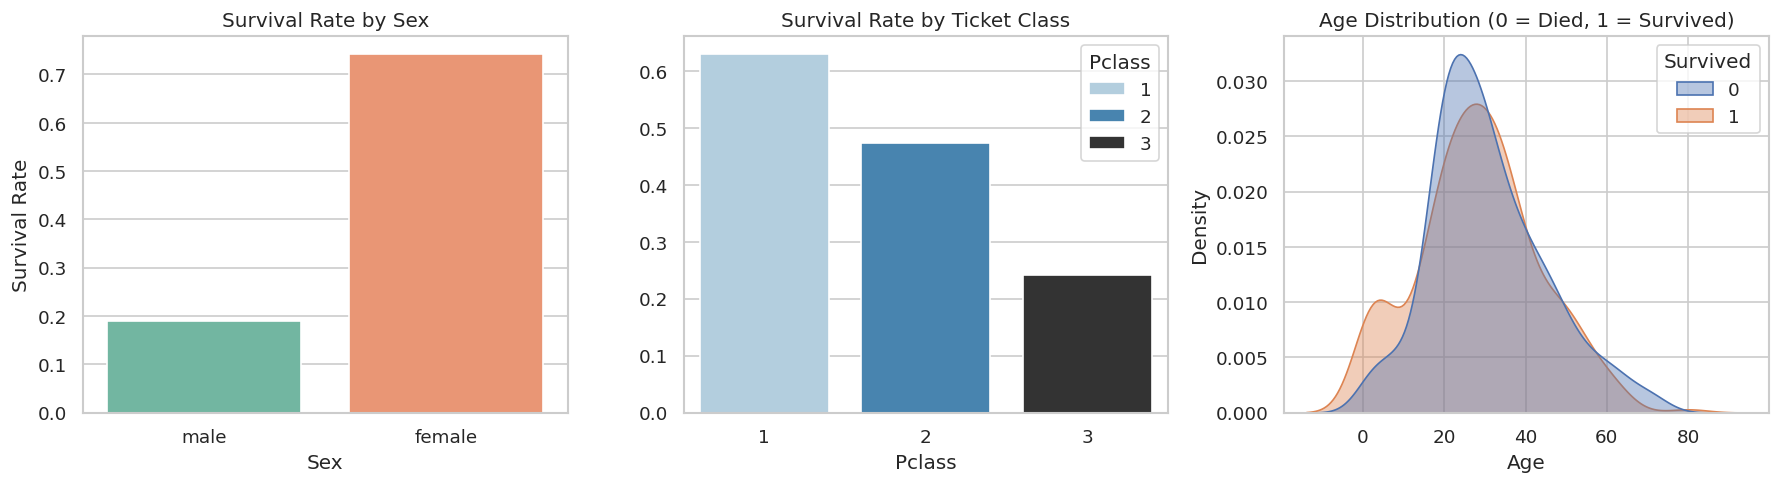

In [3]:
# Check missing values
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2)
})
display(missing[missing["missing_count"] > 0].sort_values("missing_pct", ascending=False))

# Plot the main survival drivers side-by-side
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

sns.barplot(data=df, x="Sex", y="Survived", hue="Sex", palette="Set2", errorbar=None, ax=axes[0])
axes[0].set_title("Survival Rate by Sex")
axes[0].set_ylabel("Survival Rate")

sns.barplot(data=df, x="Pclass", y="Survived", hue="Pclass", palette="Blues_d", errorbar=None, ax=axes[1])
axes[1].set_title("Survival Rate by Ticket Class")
axes[1].set_ylabel("")

sns.kdeplot(data=df, x="Age", hue="Survived", fill=True, common_norm=False, alpha=0.4, ax=axes[2])
axes[2].set_title("Age Distribution (0 = Died, 1 = Survived)")

plt.tight_layout()
plt.show()

### Feature Engineering & Pipeline Setup

Instead of modifying `df` directly, I wrapped the feature engineering into a custom `BaseEstimator` class so it can sit inside the `scikit-learn` pipeline:
1. **Titles:** Names include titles like `Mr.`, `Mrs.`, `Master.`, and nobility titles. Grouping rare titles and keeping the main ones gives the model a solid proxy for both age and social status (especially helpful when `Age` is missing).
2. **Family Size:** Combining `SibSp` and `Parch` tells us if someone was traveling alone or in a large family group (large families in 3rd class had a much harder time staying together and reaching lifeboats).
3. **Cabin Flag:** Since 77% of `Cabin` is null, we can't use the raw strings, but simply knowing whether a passenger had a recorded cabin number (`HasCabin`) correlates strongly with 1st-class upper decks.

In [4]:
class FeatureBuilder(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        # Pull title from name and group uncommon ones so one-hot encoding stays clean
        X["Title"] = X["Name"].str.extract(r" ([A-Za-z]+)\.", expand=False)
        rare = ["Lady", "Countess", "Capt", "Col", "Don", "Dr", "Major", "Rev", "Sir", "Jonkheer", "Dona"]
        X["Title"] = X["Title"].replace(rare, "Rare")
        X["Title"] = X["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})

        # Family size and solo traveler flag
        X["FamilySize"] = X["SibSp"] + X["Parch"] + 1
        X["IsAlone"] = (X["FamilySize"] == 1).astype(int)

        # Binary flag for whether cabin info exists
        X["HasCabin"] = X["Cabin"].notna().astype(int)

        # Drop raw text and ID columns we don't need anymore
        drop_cols = [c for c in ["PassengerId", "Name", "Ticket", "Cabin"] if c in X.columns]
        return X.drop(columns=drop_cols)

num_cols = ["Age", "Fare", "FamilySize"]
cat_cols = ["Pclass", "Sex", "Embarked", "Title", "IsAlone", "HasCabin"]

# RobustScaler handles the heavy right-skew in Fare better than StandardScaler
preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", RobustScaler())
    ]), num_cols),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]), cat_cols)
])

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=250, max_depth=6, random_state=42),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_depth=4, random_state=42)
}

X = df.drop(columns=["Survived"])
y = df["Survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_summary = []

for name, model in models.items():
    pipe = Pipeline([("features", FeatureBuilder()), ("prep", preprocessor), ("clf", model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["accuracy", "f1", "roc_auc"])
    cv_summary.append({
        "Model": name,
        "CV Accuracy": f"{scores['test_accuracy'].mean():.3f} (±{scores['test_accuracy'].std():.3f})",
        "CV F1": f"{scores['test_f1'].mean():.3f}",
        "CV ROC-AUC": f"{scores['test_roc_auc'].mean():.3f}"
    })

pd.DataFrame(cv_summary)

,Model,CV Accuracy,CV F1,CV ROC-AUC
0,Logistic Regression,0.827 (±0.025),0.771,0.871
1,Random Forest,0.826 (±0.021),0.757,0.881
2,HistGradientBoosting,0.830 (±0.026),0.768,0.888


### Final Evaluation & What the Model Actually Uses

Random Forest and Gradient Boosting perform very similarly here, with Random Forest being slightly more stable across folds on this dataset size. Below is the holdout test performance along with permutation importance to see which raw columns actually drive the predictions.

Holdout Test Accuracy: 0.821
Holdout Test ROC-AUC:  0.851


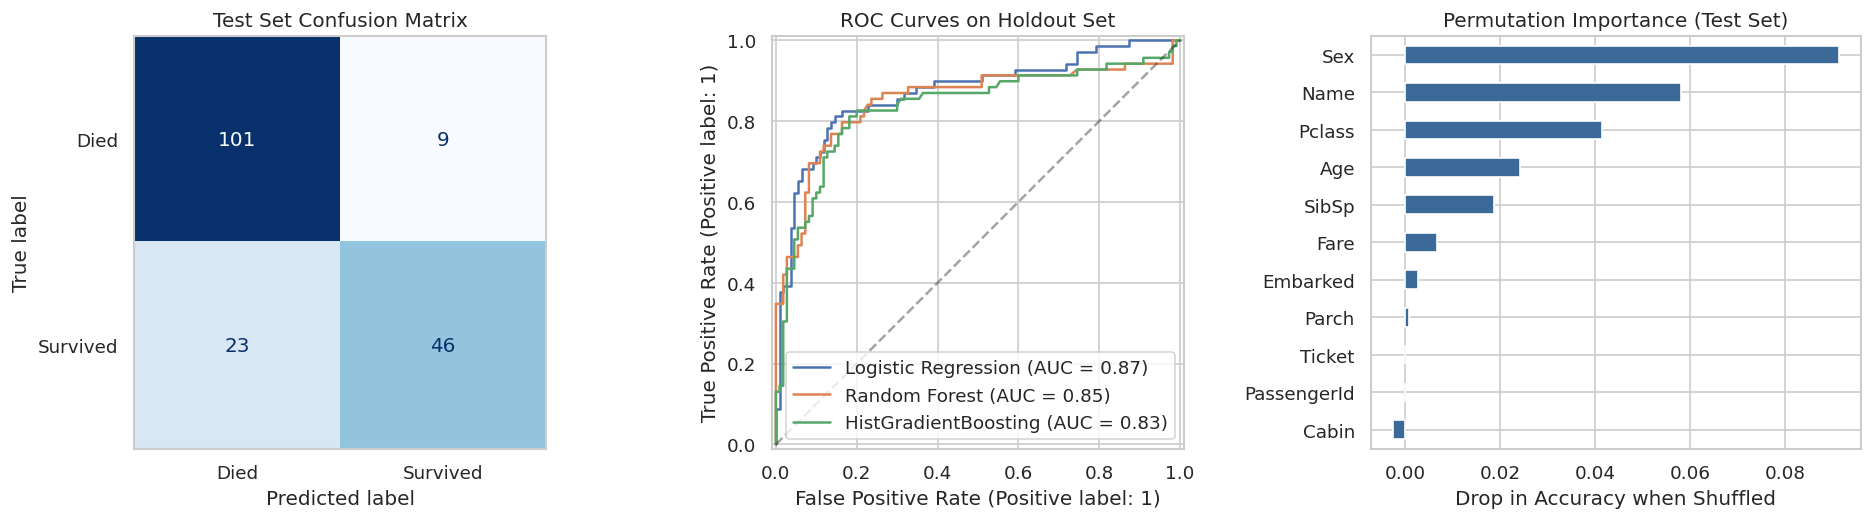

In [5]:
# Fit the final Random Forest pipeline on the training split
final_pipe = Pipeline([
    ("features", FeatureBuilder()),
    ("prep", preprocessor),
    ("clf", RandomForestClassifier(n_estimators=250, max_depth=6, random_state=42))
])
final_pipe.fit(X_train, y_train)

preds = final_pipe.predict(X_test)
probs = final_pipe.predict_proba(X_test)[:, 1]

print(f"Holdout Test Accuracy: {accuracy_score(y_test, preds):.3f}")
print(f"Holdout Test ROC-AUC:  {roc_auc_score(y_test, probs):.3f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, preds, display_labels=["Died", "Survived"], cmap="Blues", colorbar=False, ax=axes[0]
)
axes[0].set_title("Test Set Confusion Matrix")
axes[0].grid(False)

# 2. ROC Curves
for name, model in models.items():
    p = Pipeline([("features", FeatureBuilder()), ("prep", preprocessor), ("clf", model)]).fit(X_train, y_train)
    RocCurveDisplay.from_estimator(p, X_test, y_test, name=name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[1].set_title("ROC Curves on Holdout Set")

# 3. Permutation Importance
perm = permutation_importance(final_pipe, X_test, y_test, n_repeats=15, random_state=42)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
imp.plot(kind="barh", color="#3b6998", ax=axes[2])
axes[2].set_title("Permutation Importance (Test Set)")
axes[2].set_xlabel("Drop in Accuracy when Shuffled")

plt.tight_layout()
plt.savefig("results_summary.png", dpi=150)
plt.show()

# Save model & generate Kaggle submission file if running on Kaggle
joblib.dump(final_pipe, "titanic_rf_pipeline.joblib")
if os.path.exists("/kaggle/input/titanic/test.csv"):
    test_df = pd.read_csv("/kaggle/input/titanic/test.csv")
    sub = pd.DataFrame({"PassengerId": test_df["PassengerId"], "Survived": final_pipe.predict(test_df)})
    sub.to_csv("submission.csv", index=False)
    print("Generated submission.csv")

## Conclusion & Key Takeaways

* **Cross-Validation vs. Holdout Performance:** Across 5-fold stratified cross-validation, `HistGradientBoosting` achieved the highest ROC-AUC (`0.888`) and accuracy (`83.0%`), while `RandomForest` showed the tightest variance across folds (`82.6% ± 2.1%` accuracy, `0.881` ROC-AUC). On the 20% holdout test split, the Random Forest pipeline achieved **82.1% accuracy** and a **0.851 ROC-AUC**.
* **What Drove Predictions:** Permutation importance on the holdout set confirmed that `Name` (via our extracted `Title` feature), `Sex`, `Pclass`, and `Age` are the strongest drivers of survival predictions. Keeping `Cabin` as a binary `HasCabin` indicator also provided useful signal without overfitting to sparse cabin strings.
* **Zero Data Leakage:** By keeping `FeatureBuilder`, `SimpleImputer`, `RobustScaler`, and `OneHotEncoder` inside a single `scikit-learn` pipeline, the exported `titanic_rf_pipeline.joblib` artifact can take raw passenger rows and output predictions directly.

## Dataset & Credits

* **Author:** [@xaixziaaa](https://github.com/xaixziaaa)
* **Dataset:** [Kaggle — Titanic: Machine Learning from Disaster](https://www.kaggle.com/competitions/titanic) (loaded via the [Data Science Dojo CSV mirror](https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv) for zero-config execution in Colab/Jupyter).
* **Tech Stack:** Python, Pandas, NumPy, Scikit-Learn, Matplotlib, Seaborn, Joblib.